# Week 5: E-commerce Analytics

## Project Overview
This project uses Python to analyze e-commerce sales data, customer orders, product performance, and revenue patterns.

## Objectives
- Analyze e-commerce orders and sales.
- Identify top-selling products.
- Calculate total revenue and average order value.
- Compare sales across product categories.
- Explore customer purchasing patterns.
- Create charts to communicate business insights.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Expected Outcome
A complete e-commerce analytics project containing a dataset, analysis, visualizations, key findings, and documentation.

## Limitation
The project uses synthetic practice data and does not represent actual business transactions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ecommerce_data = {
    "Order_ID": list(range(1001, 1021)),
    "Product": [
        "Laptop", "Phone", "Headphones", "Tablet", "Keyboard",
        "Laptop", "Phone", "Monitor", "Headphones", "Tablet",
        "Keyboard", "Laptop", "Phone", "Monitor", "Tablet",
        "Headphones", "Keyboard", "Laptop", "Phone", "Monitor"
    ],
    "Category": [
        "Electronics", "Electronics", "Accessories", "Electronics",
        "Accessories", "Electronics", "Electronics", "Electronics",
        "Accessories", "Electronics", "Accessories", "Electronics",
        "Electronics", "Electronics", "Electronics", "Accessories",
        "Accessories", "Electronics", "Electronics", "Electronics"
    ],
    "Quantity": [
        1, 2, 3, 1, 2, 1, 1, 2, 2, 1,
        3, 1, 2, 1, 2, 4, 2, 1, 1, 2
    ],
    "Unit_Price": [
        50000, 20000, 1500, 25000, 1000,
        52000, 21000, 12000, 1800, 26000,
        1200, 51000, 22000, 12500, 24000,
        1600, 1100, 53000, 23000, 13000
    ],
    "Region": [
        "South", "North", "East", "West", "South",
        "North", "South", "East", "West", "North",
        "South", "West", "East", "South", "North",
        "West", "East", "South", "North", "West"
    ],
    "Customer_Type": [
        "New", "Returning", "New", "Returning", "New",
        "Returning", "New", "Returning", "New", "Returning",
        "New", "Returning", "New", "Returning", "New",
        "Returning", "New", "Returning", "New", "Returning"
    ]
}

ecommerce_df = pd.DataFrame(ecommerce_data)

ecommerce_df.head()

,Order_ID,Product,Category,Quantity,Unit_Price,Region,Customer_Type
0,1001,Laptop,Electronics,1,50000,South,New
1,1002,Phone,Electronics,2,20000,North,Returning
2,1003,Headphones,Accessories,3,1500,East,New
3,1004,Tablet,Electronics,1,25000,West,Returning
4,1005,Keyboard,Accessories,2,1000,South,New


In [3]:
print("Dataset Shape:", ecommerce_df.shape)

print("\nColumn Names:")
print(ecommerce_df.columns)

print("\nDataset Information:")
ecommerce_df.info()

print("\nStatistical Summary:")
ecommerce_df.describe()

Dataset Shape: (20, 7)

Column Names:
Index(['Order_ID', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Region',
       'Customer_Type'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Order_ID       20 non-null     int64
 1   Product        20 non-null     str  
 2   Category       20 non-null     str  
 3   Quantity       20 non-null     int64
 4   Unit_Price     20 non-null     int64
 5   Region         20 non-null     str  
 6   Customer_Type  20 non-null     str  
dtypes: int64(3), str(4)
memory usage: 1.8 KB

Statistical Summary:


,Order_ID,Quantity,Unit_Price
count,20.00000,20.000000,20.000000
mean,1010.50000,1.750000,20635.000000
std,5.91608,0.850696,18223.590119
min,1001.00000,1.000000,1000.000000
25%,1005.75000,1.000000,1750.000000
50%,1010.50000,2.000000,20500.000000
75%,1015.25000,2.000000,25250.000000
max,1020.00000,4.000000,53000.000000


In [4]:
ecommerce_df["Revenue"] = (
    ecommerce_df["Quantity"] * ecommerce_df["Unit_Price"]
)

print("Order Revenue:")
print(
    ecommerce_df[["Order_ID", "Product", "Quantity", "Unit_Price", "Revenue"]]
)

Order Revenue:
    Order_ID     Product  Quantity  Unit_Price  Revenue
0       1001      Laptop         1       50000    50000
1       1002       Phone         2       20000    40000
2       1003  Headphones         3        1500     4500
3       1004      Tablet         1       25000    25000
4       1005    Keyboard         2        1000     2000
5       1006      Laptop         1       52000    52000
6       1007       Phone         1       21000    21000
7       1008     Monitor         2       12000    24000
8       1009  Headphones         2        1800     3600
9       1010      Tablet         1       26000    26000
10      1011    Keyboard         3        1200     3600
11      1012      Laptop         1       51000    51000
12      1013       Phone         2       22000    44000
13      1014     Monitor         1       12500    12500
14      1015      Tablet         2       24000    48000
15      1016  Headphones         4        1600     6400
16      1017    Keyboard         

In [5]:
total_revenue = ecommerce_df["Revenue"].sum()
average_order_value = ecommerce_df["Revenue"].mean()
highest_order = ecommerce_df["Revenue"].max()
lowest_order = ecommerce_df["Revenue"].min()
total_orders = ecommerce_df["Order_ID"].nunique()
total_items_sold = ecommerce_df["Quantity"].sum()

print("E-COMMERCE SALES SUMMARY")
print("-" * 30)
print("Total Revenue: ₹", total_revenue)
print("Average Order Value: ₹", round(average_order_value, 2))
print("Highest Order Value: ₹", highest_order)
print("Lowest Order Value: ₹", lowest_order)
print("Total Orders:", total_orders)
print("Total Items Sold:", total_items_sold)

E-COMMERCE SALES SUMMARY
------------------------------
Total Revenue: ₹ 517800
Average Order Value: ₹ 25890.0
Highest Order Value: ₹ 53000
Lowest Order Value: ₹ 2000
Total Orders: 20
Total Items Sold: 35


In [6]:
product_revenue = ecommerce_df.groupby("Product")["Revenue"].sum()

product_revenue = product_revenue.sort_values(ascending=False)

print("Revenue by Product:")
print(product_revenue)

Revenue by Product:
Product
Laptop        206000
Phone         128000
Tablet         99000
Monitor        62500
Headphones     14500
Keyboard        7800
Name: Revenue, dtype: int64


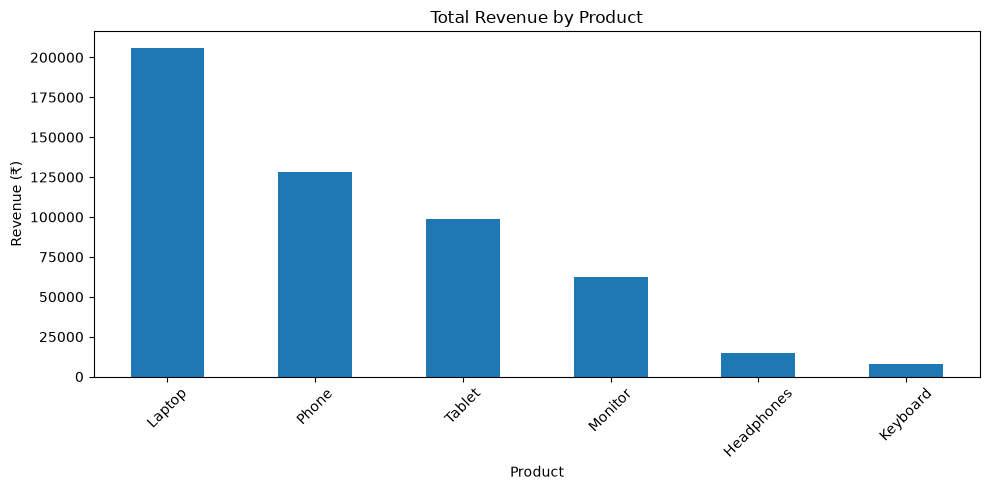

In [7]:
plt.figure(figsize=(10, 5))

product_revenue.plot(kind="bar")

plt.title("Total Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
category_revenue = ecommerce_df.groupby("Category")["Revenue"].sum()

category_revenue = category_revenue.sort_values(ascending=False)

print("Revenue by Category:")
print(category_revenue)

Revenue by Category:
Category
Electronics    495500
Accessories     22300
Name: Revenue, dtype: int64


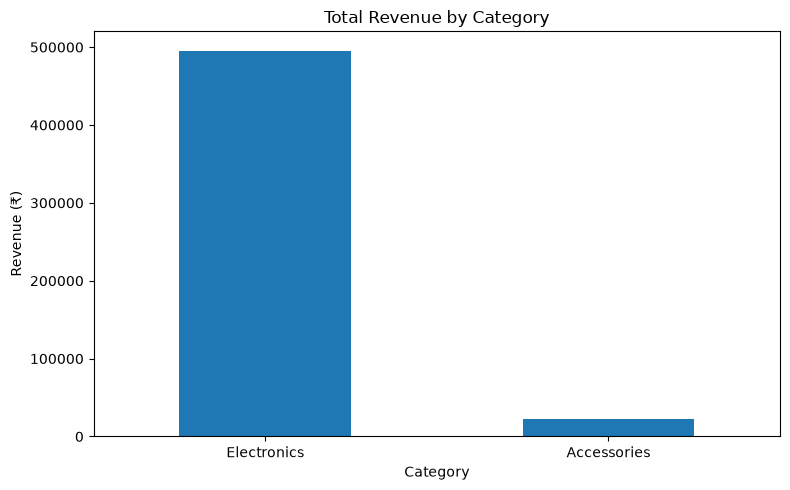

In [9]:
plt.figure(figsize=(8, 5))

category_revenue.plot(kind="bar")

plt.title("Total Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
region_revenue = ecommerce_df.groupby("Region")["Revenue"].sum()

region_revenue = region_revenue.sort_values(ascending=False)

print("Revenue by Region:")
print(region_revenue)

Revenue by Region:
Region
North    189000
South    142100
West     112000
East      74700
Name: Revenue, dtype: int64


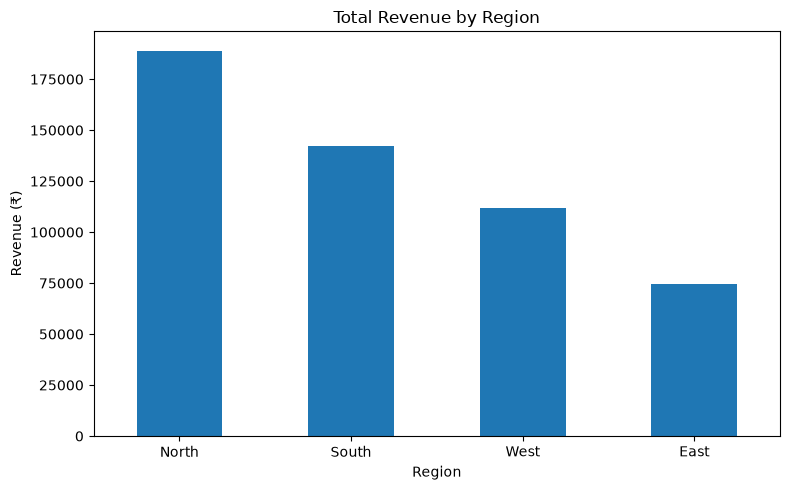

In [11]:
plt.figure(figsize=(8, 5))

region_revenue.plot(kind="bar")

plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
customer_orders = ecommerce_df["Customer_Type"].value_counts()

print("Orders by Customer Type:")
print(customer_orders)

print("\nRevenue by Customer Type:")
print(
    ecommerce_df.groupby("Customer_Type")["Revenue"]
    .sum()
)

Orders by Customer Type:
Customer_Type
New          10
Returning    10
Name: count, dtype: int64

Revenue by Customer Type:
Customer_Type
New          201900
Returning    315900
Name: Revenue, dtype: int64


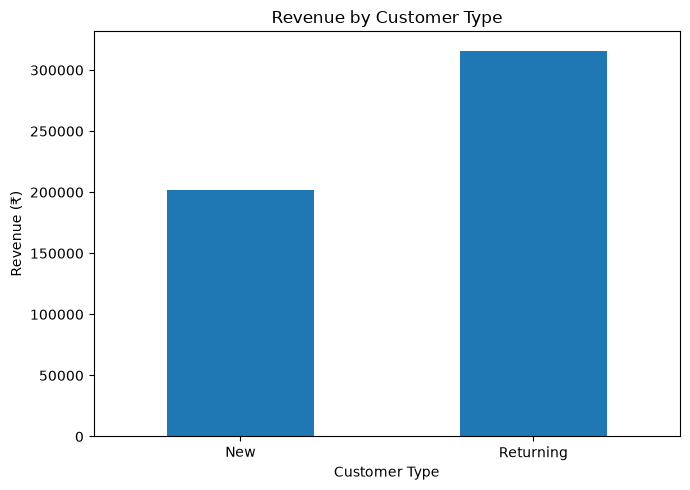

In [13]:
customer_revenue = ecommerce_df.groupby("Customer_Type")["Revenue"].sum()

plt.figure(figsize=(7, 5))

customer_revenue.plot(kind="bar")

plt.title("Revenue by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
print("TOP 5 HIGHEST-REVENUE ORDERS")

top_orders = ecommerce_df.sort_values(
    by="Revenue", ascending=False
).head(5)

print(top_orders[["Order_ID", "Product", "Quantity", "Revenue"]])

print("\nBOTTOM 5 LOWEST-REVENUE ORDERS")

bottom_orders = ecommerce_df.sort_values(
    by="Revenue", ascending=True
).head(5)

print(bottom_orders[["Order_ID", "Product", "Quantity", "Revenue"]])

TOP 5 HIGHEST-REVENUE ORDERS
    Order_ID Product  Quantity  Revenue
17      1018  Laptop         1    53000
5       1006  Laptop         1    52000
11      1012  Laptop         1    51000
0       1001  Laptop         1    50000
14      1015  Tablet         2    48000

BOTTOM 5 LOWEST-REVENUE ORDERS
    Order_ID     Product  Quantity  Revenue
4       1005    Keyboard         2     2000
16      1017    Keyboard         2     2200
10      1011    Keyboard         3     3600
8       1009  Headphones         2     3600
2       1003  Headphones         3     4500


In [15]:
print("MISSING VALUES")
print(ecommerce_df.isnull().sum())

print("\nDUPLICATE ROWS:")
print(ecommerce_df.duplicated().sum())

print("\nDUPLICATE ORDER IDs:")
print(ecommerce_df["Order_ID"].duplicated().sum())

print("\nFINAL DATASET SHAPE:")
print(ecommerce_df.shape)

MISSING VALUES
Order_ID         0
Product          0
Category         0
Quantity         0
Unit_Price       0
Region           0
Customer_Type    0
Revenue          0
dtype: int64

DUPLICATE ROWS:
0

DUPLICATE ORDER IDs:
0

FINAL DATASET SHAPE:
(20, 8)


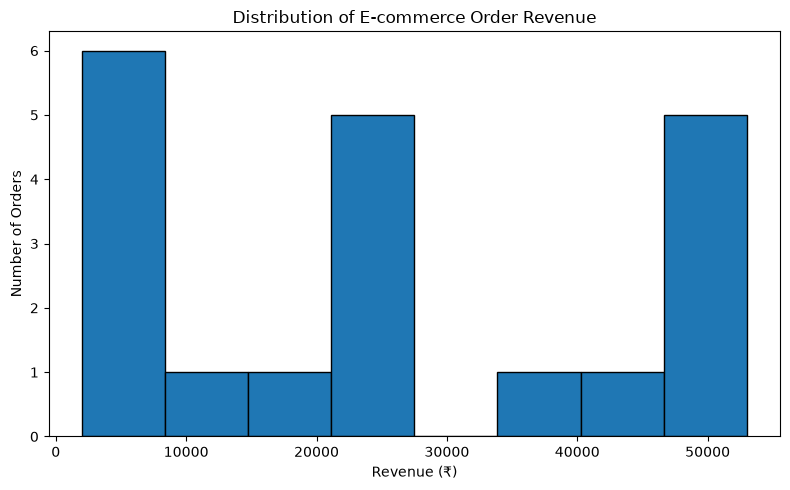

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(ecommerce_df["Revenue"], bins=8, edgecolor="black")

plt.title("Distribution of E-commerce Order Revenue")
plt.xlabel("Revenue (₹)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

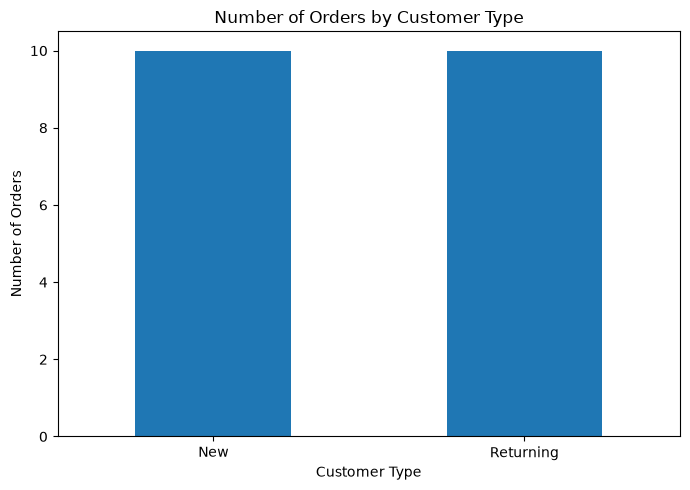

In [17]:
plt.figure(figsize=(7, 5))

customer_orders.plot(kind="bar")

plt.title("Number of Orders by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

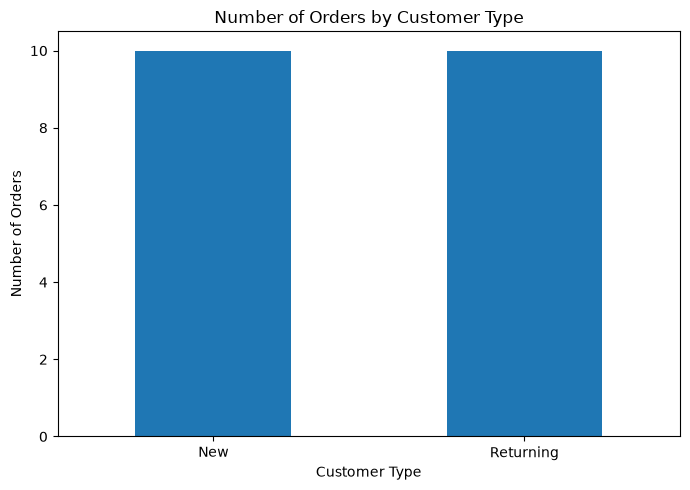

In [18]:
plt.figure(figsize=(7, 5))

customer_orders.plot(kind="bar")

plt.title("Number of Orders by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

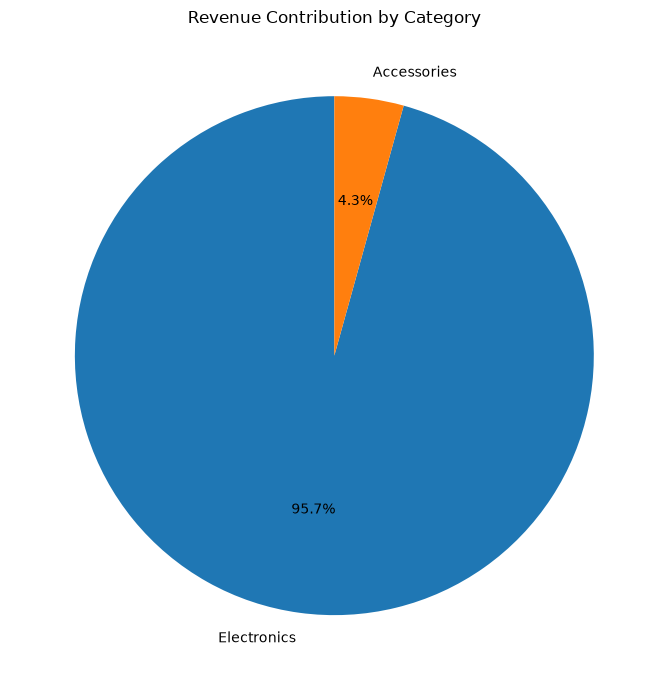

In [19]:
plt.figure(figsize=(7, 7))

plt.pie(
    category_revenue,
    labels=category_revenue.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Contribution by Category")
plt.tight_layout()
plt.show()

In [20]:
average_product_revenue = (
    ecommerce_df.groupby("Product")["Revenue"].mean()
)

average_product_revenue = average_product_revenue.sort_values(
    ascending=False
)

print("Average Revenue by Product:")
print(average_product_revenue.round(2))

Average Revenue by Product:
Product
Laptop        51500.00
Tablet        33000.00
Phone         32000.00
Monitor       20833.33
Headphones     4833.33
Keyboard       2600.00
Name: Revenue, dtype: float64


In [21]:
product_summary = ecommerce_df.groupby("Product").agg(
    Total_Quantity=("Quantity", "sum"),
    Average_Quantity=("Quantity", "mean"),
    Average_Unit_Price=("Unit_Price", "mean"),
    Total_Revenue=("Revenue", "sum")
)

print("PRODUCT PERFORMANCE SUMMARY")
print(product_summary.round(2))

PRODUCT PERFORMANCE SUMMARY
            Total_Quantity  Average_Quantity  Average_Unit_Price  \
Product                                                            
Headphones               9              3.00             1633.33   
Keyboard                 7              2.33             1100.00   
Laptop                   4              1.00            51500.00   
Monitor                  5              1.67            12500.00   
Phone                    6              1.50            21500.00   
Tablet                   4              1.33            25000.00   

            Total_Revenue  
Product                    
Headphones          14500  
Keyboard             7800  
Laptop             206000  
Monitor             62500  
Phone              128000  
Tablet              99000  


In [22]:
units_sold = ecommerce_df.groupby("Product")["Quantity"].sum()

units_sold = units_sold.sort_values(ascending=False)

print("Total Units Sold by Product:")
print(units_sold)

Total Units Sold by Product:
Product
Headphones    9
Keyboard      7
Phone         6
Monitor       5
Laptop        4
Tablet        4
Name: Quantity, dtype: int64


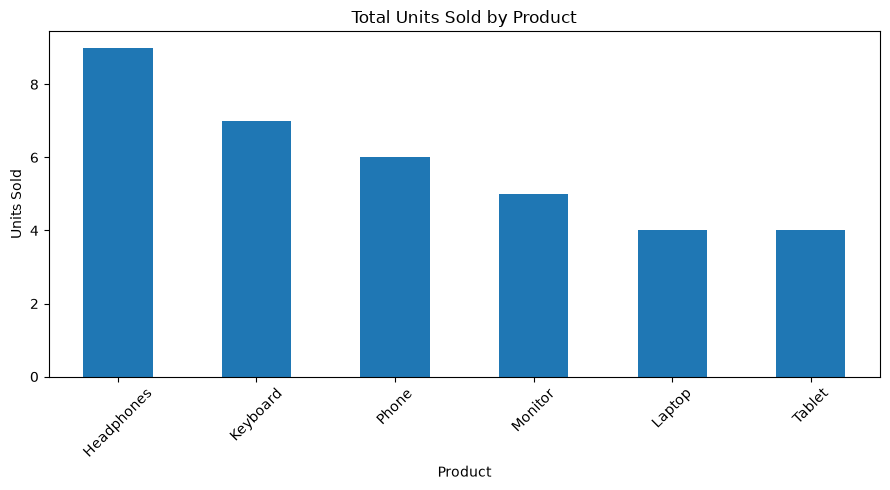

In [23]:
plt.figure(figsize=(9, 5))

units_sold.plot(kind="bar")

plt.title("Total Units Sold by Product")
plt.xlabel("Product")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

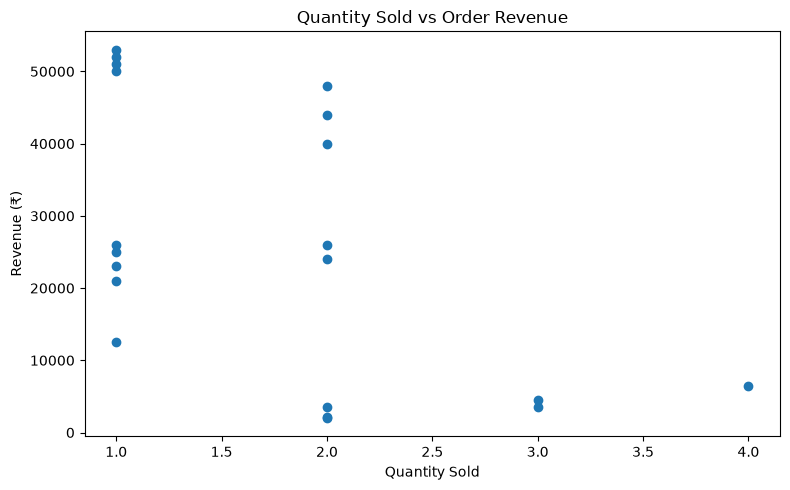

In [24]:
plt.figure(figsize=(8, 5))

plt.scatter(
    ecommerce_df["Quantity"],
    ecommerce_df["Revenue"]
)

plt.title("Quantity Sold vs Order Revenue")
plt.xlabel("Quantity Sold")
plt.ylabel("Revenue (₹)")
plt.tight_layout()
plt.show()

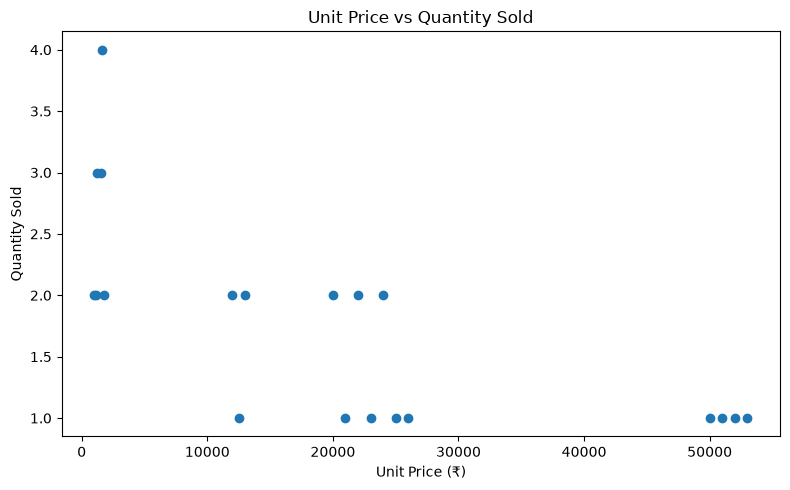

In [25]:
plt.figure(figsize=(8, 5))

plt.scatter(
    ecommerce_df["Unit_Price"],
    ecommerce_df["Quantity"]
)

plt.title("Unit Price vs Quantity Sold")
plt.xlabel("Unit Price (₹)")
plt.ylabel("Quantity Sold")
plt.tight_layout()
plt.show()

In [26]:
product_contribution = (
    ecommerce_df.groupby("Product")["Revenue"].sum()
    / ecommerce_df["Revenue"].sum()
    * 100
)

product_contribution = product_contribution.sort_values(
    ascending=False
)

print("Product Revenue Contribution (%):")
print(product_contribution.round(2))

Product Revenue Contribution (%):
Product
Laptop        39.78
Phone         24.72
Tablet        19.12
Monitor       12.07
Headphones     2.80
Keyboard       1.51
Name: Revenue, dtype: float64


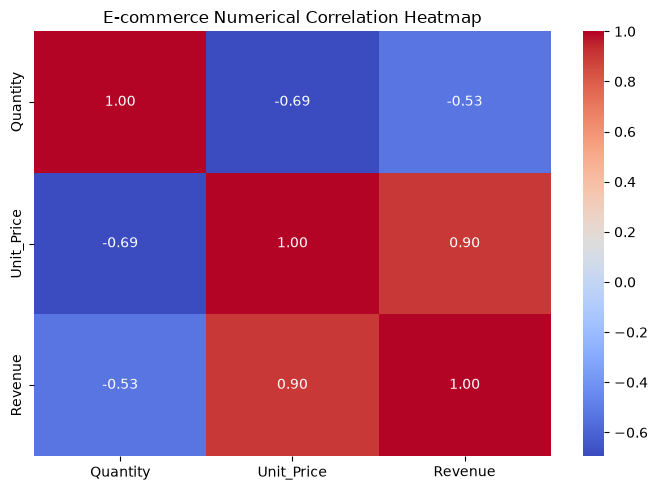

In [27]:
numerical_data = ecommerce_df[
    ["Quantity", "Unit_Price", "Revenue"]
]

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("E-commerce Numerical Correlation Heatmap")
plt.tight_layout()
plt.show()

In [28]:
ecommerce_df.to_csv("ecommerce_data.csv", index=False)

print("E-commerce dataset exported successfully!")

E-commerce dataset exported successfully!